# Paper Example 1: Forward Simulations Compared with TracerLPM

This notebook walks through Example 1 of the PyTracerLab paper (Rudolph et al.,
*Environmental Modelling & Software*). Four lumped parameter models are run forward
with three parameter sets each:

- piston flow model (PM),
- exponential model (EM),
- exponential piston flow model (EPM),
- dispersion model (DM).

The tracer input is the yearly tritium time series of Example 3 of TracerLPM
(Jurgens et al., 2012). The results are compared with the results of TracerLPM for
the same input and parameters.

The script [`example_1.py`](https://github.com/iGW-TU-Dresden/PyTracerLab/blob/main/docs/examples/paper/example_1.py) in the same folder produces the
figure and the numbers of the paper. This notebook shows the same steps one by one.
All data files are in the folder
[`docs/examples/paper`](https://github.com/iGW-TU-Dresden/PyTracerLab/tree/main/docs/examples/paper).

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import PyTracerLab as lab

## 1. Load the Input Series and the TracerLPM Results

`lab.read_series` reads a CSV file with one row per date and one column per tracer.
The input file has one value per year (1850-2020). The TracerLPM results of each
parameter set are stored in one file per set, with one column per model.

Input: ['3H'] 171 time steps, 1850 - 2020
TracerLPM results: ['PM', 'EM', 'EPM', 'DM'] 1950 - 2010


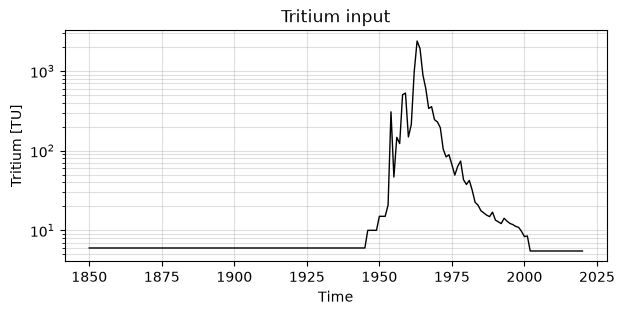

In [2]:
inp = lab.read_series("tritium_input.csv")
ref = [lab.read_series(f"example_1_tracerlpm_set{i}.csv") for i in (1, 2, 3)]
print("Input:", inp.tracers, len(inp), "time steps,", inp.times[0].year, "-", inp.times[-1].year)
print("TracerLPM results:", ref[0].tracers, ref[0].times[0].year, "-", ref[0].times[-1].year)

years_in = np.array([t.year for t in inp.times])
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(years_in, inp.values, c="k", lw=1.0)  # one tracer: 1-D array
ax.set(xlabel="Time", ylabel="Tritium [TU]", yscale="log", title="Tritium input")
ax.grid(True, which="both", alpha=0.4)
plt.show()

## 2. Model Set-up

A model needs the time step (here 1 yr), the decay constant of the tracer, the input
series, and the concentration of the water that recharged before the start of the
input series (steady-state input; here 6 TU before 1850, as in TracerLPM). Each model
consists of a single unit with a fraction of 1 (no mixing).

The parameter sets are those used in TracerLPM. TracerLPM describes the EPM by the
ratio of the exponential to the total volume; PyTracerLab uses $\eta = 1 + $ ratio.

In [3]:
SETS = [
    {"mtt": 15.0, "eta": 1.5, "DP": 0.5},
    {"mtt": 20.0, "eta": 1.7, "DP": 0.7},
    {"mtt": 30.0, "eta": 1.8, "DP": 0.8},
]
UNITS = {
    "PM": lambda p: lab.PMUnit(mtt=p["mtt"]),
    "EM": lambda p: lab.EMUnit(mtt=p["mtt"]),
    "EPM": lambda p: lab.EPMUnit(mtt=p["mtt"], eta=p["eta"]),
    "DM": lambda p: lab.DMUnit(mtt=p["mtt"], DP=p["DP"]),
}


def simulate(unit):
    m = lab.Model(
        dt=1.0,
        lambda_=lab.decay_constant("Tritium"),
        input_series=inp.values,
        steady_state_input=6.0,
        time_steps=inp.times,
    )
    m.add_unit(unit, fraction=1.0)
    return m.simulate()

## 3. Simulate and Compare with TracerLPM

Each model is simulated for the whole input period; the comparison uses the years
for which TracerLPM results are available (1950-2010).

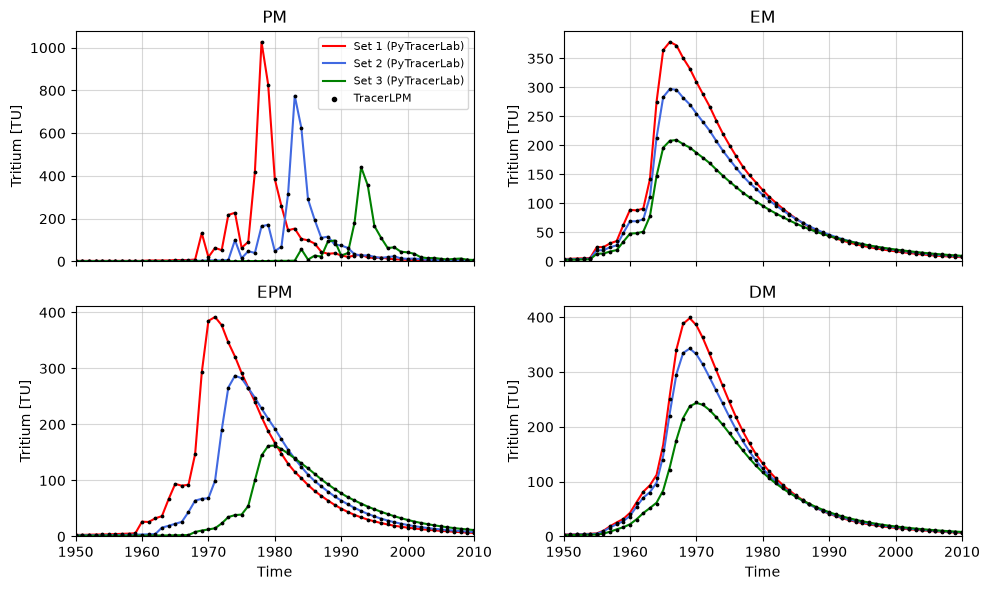

Model  Set  max |difference| [TU]  RMSE [TU]
PM       1                  0.000      0.000
PM       2                  0.000      0.000
PM       3                  0.000      0.000
EM       1                  0.373      0.147
EM       2                  0.251      0.104
EM       3                  0.148      0.065
EPM      1                  0.030      0.011
EPM      2                  0.024      0.009
EPM      3                  0.017      0.007
DM       1                  9.873      2.009
DM       2                  8.380      1.694
DM       3                  5.083      1.169


In [4]:
sel = np.isin(inp.times, ref[0].times)
years = years_in[sel]
colors = ["red", "royalblue", "green"]

fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True)
rows = []
for j, (ax, (name, make)) in enumerate(zip(axes.flat, UNITS.items())):
    for i, p in enumerate(SETS):
        sim = simulate(make(p))[sel]
        bench = ref[i].values[:, j]
        diff = sim - bench
        rows.append((name, i + 1, np.abs(diff).max(), np.sqrt(np.mean(diff**2))))
        ax.plot(years, sim, c=colors[i], lw=1.5, label=f"Set {i + 1} (PyTracerLab)")
        ax.scatter(years, bench, c="k", marker=".", s=12, zorder=10)
    ax.set(title=name, ylabel="Tritium [TU]", xlim=(years[0], years[-1]), ylim=(0, None))
    ax.grid(True, alpha=0.5)
axes[0, 0].scatter([], [], c="k", marker=".", label="TracerLPM")
axes[0, 0].legend(fontsize=8)
for ax in axes[1]:
    ax.set_xlabel("Time")
fig.tight_layout()
plt.show()

print("Model  Set  max |difference| [TU]  RMSE [TU]")
for name, s, d, r in rows:
    print(f"{name:5s}  {s:3d}  {d:21.3f}  {r:9.3f}")

For the PM, the EM and the EPM, PyTracerLab integrates the travel time distribution
exactly over each time step, as TracerLPM does with its analytical solutions; the
results agree within a few tenths of a TU. For the DM, differences of up to about
10 TU (2.5 % of the simulated concentration) remain near the bomb peak. They are not
caused by the time discretisation in PyTracerLab (see the paper).

## Further Reading

- Tutorials 1 and 6 show forward simulations with synthetic data and the effect of
  the time step.
- The user guide describes all model units and the file format of the input series.